In [1]:
import numpy as np
import pandas as pd


data = np.load(r'C:\Users\GiovanniPiva\OneDrive - Rationis Srl\Desktop\rBergomi-Neural-Network\data\surfaces.npz')
print(data.files)

for key in data.files:
    arr = data[key]
    print(f"{key}: shape={arr.shape}, ndim={arr.ndim}")

['theta', 'implied_vol', 'implied_vol_stderr', 'split', 'grid', 'mc']
theta: shape=(18111, 4), ndim=2
implied_vol: shape=(18111, 8, 10), ndim=3
implied_vol_stderr: shape=(18111, 8, 10), ndim=3
split: shape=(18111,), ndim=1
grid: shape=(), ndim=0
mc: shape=(), ndim=0


In [2]:
# Theta: 4 colonne
df_theta = pd.DataFrame(
    data["theta"],
    columns=["theta_0", "theta_1", "theta_2", "theta_3"]
)

# Implied volatility: 80 colonne
df_iv = pd.DataFrame(
    data["implied_vol"].reshape(18111, -1),
    columns=[f"iv_{i}_{j}" for i in range(8) for j in range(10)]
)

# Standard error: 80 colonne
df_stderr = pd.DataFrame(
    data["implied_vol_stderr"].reshape(18111, -1),
    columns=[f"stderr_{i}_{j}" for i in range(8) for j in range(10)]
)

# Split
df_split = pd.DataFrame({"split": data["split"]})

# DataFrame finale
df = pd.concat(
    [df_theta, df_iv, df_stderr, df_split],
    axis=1
)

display(df)

,theta_0,theta_1,theta_2,theta_3,iv_0_0,iv_0_1,iv_0_2,iv_0_3,iv_0_4,iv_0_5,...,stderr_7_1,stderr_7_2,stderr_7_3,stderr_7_4,stderr_7_5,stderr_7_6,stderr_7_7,stderr_7_8,stderr_7_9,split
0,0.351915,1.502431,-0.881303,0.061557,0.281222,0.274471,0.267585,0.260573,0.253454,0.246250,...,0.001299,0.001165,0.001039,0.000920,0.000807,0.000691,0.000560,0.000405,0.000244,train
1,0.156732,2.297796,-0.347394,0.103480,0.338518,0.328524,0.318881,0.309730,0.301250,0.293657,...,0.000792,0.000720,0.000654,0.000595,0.000550,0.000526,0.000519,0.000525,0.000544,train
2,0.100060,1.175046,-0.695520,0.030784,0.211079,0.203969,0.196847,0.189735,0.182659,0.175658,...,0.000919,0.000815,0.000719,0.000627,0.000536,0.000444,0.000354,0.000274,0.000214,train
3,0.299303,2.876660,-0.533519,0.084179,0.320340,0.309495,0.298772,0.288250,0.278037,0.268283,...,0.000653,0.000548,0.000454,0.000375,0.000311,0.000274,0.000276,0.000298,0.000336,train
4,0.268450,1.354481,-0.244193,0.080462,0.295367,0.291574,0.288005,0.284689,0.281654,0.278928,...,0.000406,0.000338,0.000276,0.000226,0.000197,0.000192,0.000203,0.000215,0.000225,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18106,0.360605,1.220469,-0.339914,0.181798,0.434349,0.431597,0.428934,0.426366,0.423896,0.421531,...,0.000517,0.000436,0.000357,0.000284,0.000223,0.000183,0.000173,0.000187,0.000212,ood
18107,0.072810,3.891666,-0.929348,0.026856,0.208593,0.191078,0.172972,0.154158,0.134593,0.114780,...,0.001822,0.001609,0.001402,0.001205,0.001032,0.000936,0.001146,0.001590,0.002138,ood
18108,0.082285,0.551516,-0.598998,0.043909,0.226170,0.223106,0.220062,0.217045,0.214065,0.211131,...,0.000736,0.000693,0.000650,0.000606,0.000561,0.000516,0.000469,0.000423,0.000378,ood
18109,0.276364,3.335503,-0.208492,0.173651,0.404954,0.395769,0.387194,0.379380,0.372500,0.366728,...,0.000759,0.000720,0.000684,0.000651,0.000625,0.000617,0.000633,0.000670,0.000723,ood


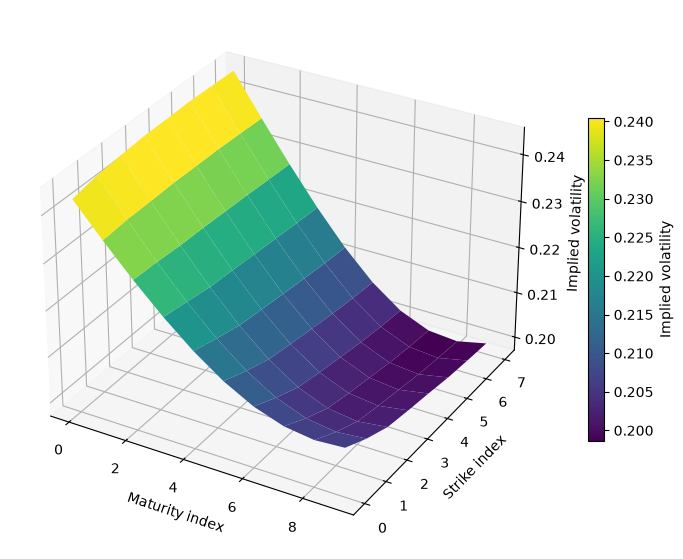

In [3]:
import matplotlib.pyplot as plt

iv = data["implied_vol"]

i = 10
Z = iv[i]  # Shape (8, 10)

# Coordinate della griglia
X, Y = np.meshgrid(
    np.arange(Z.shape[1]),
    np.arange(Z.shape[0])
)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    edgecolor="none"
)

ax.set_xlabel("Maturity index")
ax.set_ylabel("Strike index")
ax.set_zlabel("Implied volatility")

fig.colorbar(surf, ax=ax, shrink=0.6, label="Implied volatility")

plt.show()

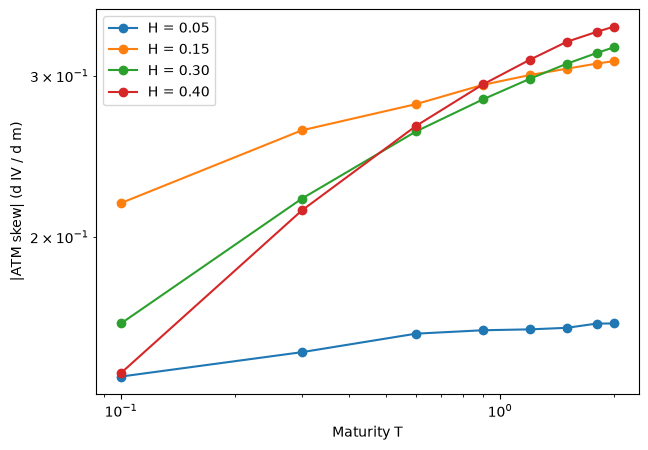

H vero = 0.050   pendenza = 0.055
H vero = 0.147   pendenza = 0.134
H vero = 0.302   pendenza = 0.259
H vero = 0.400   pendenza = 0.333


In [4]:
mats = np.array([0.1, 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.0])
m = np.array([-0.30, -0.25, -0.20, -0.15, -0.10, -0.05, 0.0, 0.05, 0.10, 0.15])

iv = data["implied_vol"]
theta = data["theta"]            # colonne: H, eta, rho, xi0
train = data["split"] == "train"

# skew ATM rispetto a m: differenza centrale intorno a m = 0 (indice 6)
skew = (iv[:, :, 7] - iv[:, :, 5]) / (m[7] - m[5])    # (N, 8)

# scegli 4 superfici con H diversi, ma eta e rho simili, per isolare l'effetto di H
idx = np.where(train & (np.abs(theta[:, 1] - 2.0) < 0.2) & (np.abs(theta[:, 2] + 0.7) < 0.1))[0]
idx = idx[np.argsort(theta[idx, 0])]
idx = idx[np.linspace(0, len(idx) - 1, 4).astype(int)]

fig, ax = plt.subplots(figsize=(7, 5))
for i in idx:
    ax.loglog(mats, -skew[i], "o-", label=f"H = {theta[i, 0]:.2f}")
ax.set_xlabel("Maturity T")
ax.set_ylabel("|ATM skew| (d IV / d m)")
ax.legend()
plt.show()

# pendenza stimata sulle 4 scadenze più brevi, da confrontare con H
for i in idx:
    slope = np.polyfit(np.log(mats[:4]), np.log(-skew[i, :4]), 1)[0]
    print(f"H vero = {theta[i, 0]:.3f}   pendenza = {slope:.3f}")
